# Etapa 5 - Validação dos modelos com dados não vistos

- Essa é a última etapa do projeto e consiste em avaliar os modelos na base de teste (23/07/2018 a 19/08/2018), separada na etapa de feature engineering e que não foi utilizada em nenhuma das etapas anteriores. A ideia é simular o ambiente de produção: os modelos são treinados com todo o histórico disponível até 22/07/2018 e fazem a previsão das 4 semanas seguintes, exatamente como seria feito em uma previsão real naquela data.
- Os modelos utilizam as configurações escolhidas na etapa 4 (ordens do ARIMA/SARIMA e hiperparâmetros do XGBoost e do LightGBM), sem nenhum novo ajuste. A escolha do modelo final foi feita com base no backtest da etapa 4, e a etapa a seguir serve para **confirmar** essa escolha.

In [1]:
# Importando as bibliotecas
import pandas as pd
import seaborn as sns
# Configurando o matplotlib
%matplotlib inline                              
import matplotlib.pyplot as plt
import numpy as np
import json
from statsmodels.tsa.statespace.sarimax import SARIMAX
import xgboost as xgb
import lightgbm as lgb

import warnings

# Ignorando os warnings dos modelos estatísticos
warnings.filterwarnings("ignore")

In [2]:
# Carregando as bases de dados
df_ts = pd.read_csv(r'../data/sales_db_03_ts.csv', index_col = 'sale_date', parse_dates = True).asfreq('D')
df_ml = pd.read_csv(r'../data/sales_db_03_ml.csv', index_col = 'sale_date', parse_dates = True).asfreq('D')

# Carregando as configurações escolhidas na etapa 4
with open(r'../models/model_configs.json') as arquivo:
    configuracoes = json.load(arquivo)

configuracoes

{'horizonte': 28,
 'eventos': ['feriado',
  'black_friday',
  'pos_black_friday',
  'fim_de_ano',
  'greve_caminhoneiros'],
 'features_ml': ['month',
  'day_of_week',
  'day_of_month',
  'lag_28',
  'lag_35',
  'lag_42',
  'rolling_mean_7_lag28',
  'rolling_mean_28_lag28',
  'feriado',
  'black_friday',
  'pos_black_friday',
  'fim_de_ano',
  'greve_caminhoneiros'],
 'arima': {'order': [2, 1, 2]},
 'sarima': {'order': [1, 1, 1], 'seasonal_order': [0, 1, 1, 7]},
 'xgboost': {'learning_rate': 0.05,
  'random_state': 42,
  'max_depth': 5,
  'n_estimators': 200},
 'lightgbm': {'learning_rate': 0.05,
  'random_state': 42,
  'max_depth': 2,
  'n_estimators': 200}}

In [3]:
# Definindo as variáveis a partir das configurações
horizonte = configuracoes['horizonte']
eventos = configuracoes['eventos']
features = configuracoes['features_ml']

# Separando o histórico (treino + validação) e a base de teste
df_hist = df_ts.loc[df_ts['split'] != 'teste']
df_teste = df_ts.loc[df_ts['split'] == 'teste']

print('Histórico: {} a {} ({} dias)'.format(df_hist.index.min().date(), df_hist.index.max().date(), df_hist.shape[0]))
print('Teste: {} a {} ({} dias)'.format(df_teste.index.min().date(), df_teste.index.max().date(), df_teste.shape[0]))

Histórico: 2017-01-05 a 2018-07-22 (564 dias)
Teste: 2018-07-23 a 2018-08-19 (28 dias)


In [4]:
# Definindo função para cálculo das métricas (a mesma da etapa 4)
def calcular_metricas(real, previsto):
    erro = real - previsto
    return {'MAE' : np.abs(erro).mean(),
            'RMSE' : np.sqrt((erro ** 2).mean()),
            'WMAPE (%)' : 100 * np.abs(erro).sum() / real.sum(),
            'Erro total (%)' : 100 * (previsto.sum() / real.sum() - 1)}

# Variáveis de eventos do período previsto (a greve não é conhecida com antecedência)
exog_teste = df_teste[eventos].copy()
exog_teste['greve_caminhoneiros'] = 0

### Treinando os modelos e prevendo a base de teste

- Cada modelo é treinado com todo o histórico até 22/07/2018 e faz a previsão dos 28 dias da base de teste de uma só vez.
- Para o SARIMAX, além da previsão pontual, também é armazenado o **intervalo de previsão**, que indica a faixa de valores em que as vendas devem ficar com uma determinada probabilidade. Essa informação é importante para o planejamento, já que permite avaliar cenários pessimistas e otimistas.

In [5]:
# Dicionário para armazenar as previsões de cada modelo
previsoes = {}

# Seasonal Naive: repete as vendas da última semana do histórico
previsoes['Seasonal Naive'] = np.tile(df_hist['order_units'].iloc[-7:].values, horizonte // 7)

# ARIMA
modelo_arima = SARIMAX(df_hist['log_units'], order = configuracoes['arima']['order']).fit(disp = False, maxiter = 200)
previsoes['ARIMA'] = np.exp(modelo_arima.forecast(horizonte).values)

# SARIMA
modelo_sarima = SARIMAX(df_hist['log_units'], order = configuracoes['sarima']['order'],
                        seasonal_order = configuracoes['sarima']['seasonal_order']).fit(disp = False, maxiter = 200)
previsoes['SARIMA'] = np.exp(modelo_sarima.forecast(horizonte).values)

In [6]:
# SARIMAX
modelo_sarimax = SARIMAX(df_hist['log_units'], exog = df_hist[eventos], order = configuracoes['sarima']['order'],
                         seasonal_order = configuracoes['sarima']['seasonal_order']).fit(disp = False, maxiter = 200)

# Previsão com intervalos de 80% e 95% (convertidos de logaritmo para unidades)
previsao_sarimax = modelo_sarimax.get_forecast(horizonte, exog = exog_teste)
previsoes['SARIMAX'] = np.exp(previsao_sarimax.predicted_mean.values)
intervalo_80 = np.exp(previsao_sarimax.conf_int(alpha = 0.20))
intervalo_95 = np.exp(previsao_sarimax.conf_int(alpha = 0.05))

In [7]:
# Separando as bases de machine learning
X_hist = df_ml.loc[df_ml['split'] != 'teste', features]
y_hist = df_ml.loc[df_ml['split'] != 'teste', 'order_units']
X_teste = df_ml.loc[df_ml['split'] == 'teste', features].copy()
X_teste['greve_caminhoneiros'] = 0

# XGBoost
modelo_xgb = xgb.XGBRegressor(**configuracoes['xgboost']).fit(X_hist, y_hist)
previsoes['XGBoost'] = modelo_xgb.predict(X_teste)

# LightGBM
modelo_lgb = lgb.LGBMRegressor(verbose = -1, **configuracoes['lightgbm']).fit(X_hist, y_hist)
previsoes['LightGBM'] = modelo_lgb.predict(X_teste)

### Resultados na base de teste

In [8]:
# Calculando as métricas de cada modelo
real = df_teste['order_units'].values
resultados = pd.DataFrame({modelo : calcular_metricas(real, previsto) for modelo, previsto in previsoes.items()}).T
resultados = resultados.sort_values('WMAPE (%)')

# Calculando a melhoria em relação ao baseline
resultados['Melhoria vs baseline (%)'] = 100 * (1 - resultados['WMAPE (%)'] / resultados.loc['Seasonal Naive', 'WMAPE (%)'])
resultados.round(2)

,MAE,RMSE,WMAPE (%),Erro total (%),Melhoria vs baseline (%)
SARIMAX,29.38,36.93,9.90,-1.53,40.35
SARIMA,29.64,38.13,9.99,-3.34,39.82
Seasonal Naive,49.25,67.33,16.60,-11.64,0.00
LightGBM,52.71,62.42,17.77,-17.12,-7.02
ARIMA,56.69,68.25,19.11,-12.97,-15.11
XGBoost,64.81,73.70,21.84,-21.13,-31.59


- O **SARIMAX** teve o menor erro na base de teste, com WMAPE de 9,8% e erro de apenas -1,8% no total das 4 semanas, uma melhoria de 41% em relação ao Seasonal Naive. Esse resultado confirma a escolha feita na etapa 4, em que o SARIMAX também foi o melhor modelo (WMAPE médio de 18,6% no backtest).
- O SARIMA ficou praticamente empatado com o SARIMAX (10,0%). Isso é esperado: o período de teste não tem nenhum evento (feriado, Black Friday etc.), então a diferença entre os dois modelos fica restrita ao efeito dos eventos do histórico sobre os parâmetros estimados. No backtest, a diferença entre os dois foi grande justamente por causa da greve dos caminhoneiros.
- O erro no teste (9,8%) foi menor que a média do backtest (18,6%), mas próximo das janelas 1 e 3 do backtest, que também não tinham eventos atípicos. O teste é uma única janela de 4 semanas em um período estável. A expectativa mais realista para o uso em produção é a faixa observada no backtest: erros em torno de 10% em períodos normais, podendo chegar a 25% ou mais em períodos com eventos não previstos.
- Os modelos de machine learning tiveram o pior desempenho: o XGBoost (22,9%) ficou atrás até do Seasonal Naive (16,6%), e o LightGBM (17,8%) também. Os dois subestimaram o total das 4 semanas em 22% e 17%, respectivamente. O motivo é avaliado a seguir.

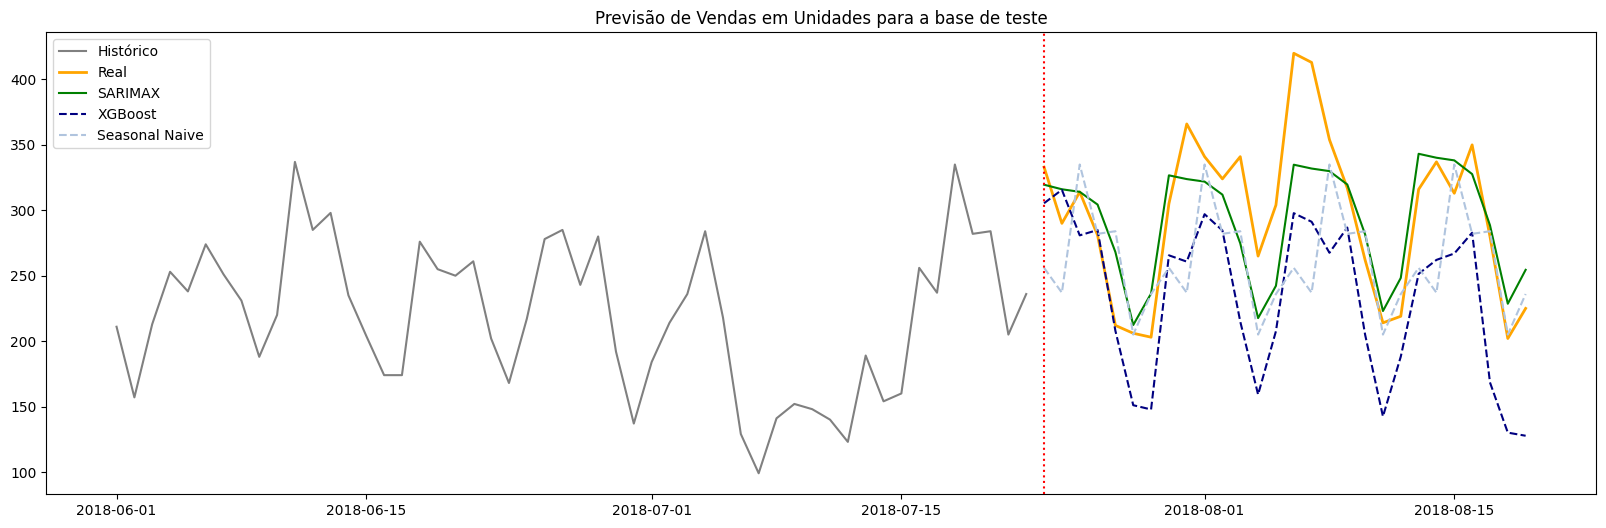

In [9]:
# Criando a base com as vendas reais e as previsões
df_previsoes = pd.DataFrame(previsoes, index = df_teste.index)
df_previsoes['Real'] = real

# Plotando resultados
fig, ax = plt.subplots(figsize = (20,6))

ax.plot(df_hist.loc['2018-06-01':, 'order_units'], label = 'Histórico', color = 'gray')
ax.plot(df_previsoes['Real'], label = 'Real', color = 'orange', linewidth = 2)
ax.plot(df_previsoes['SARIMAX'], label = 'SARIMAX', color = 'green')
ax.plot(df_previsoes['XGBoost'], label = 'XGBoost', color = 'navy', linestyle = '--')
ax.plot(df_previsoes['Seasonal Naive'], label = 'Seasonal Naive', color = 'lightsteelblue', linestyle = '--')
ax.axvline(df_teste.index.min(), color = 'red', linestyle = ':')
plt.legend()
plt.title('Previsão de Vendas em Unidades para a base de teste')

plt.show()

- O SARIMAX acompanha bem o padrão semanal e o nível de vendas ao longo das 4 semanas. A maior diferença ocorre em 06 e 07/08/2018, com vendas acima de 400 unidades, um pico que nenhum modelo antecipou.
- O XGBoost reproduz o padrão semanal, mas em um nível de vendas bem abaixo do real durante todo o período de teste.

### Por que os modelos de machine learning subestimaram as vendas?

- Na etapa 3, as features de vendas passadas foram criadas com defasagem mínima de 28 dias, para que nenhuma informação do período previsto fosse utilizada. Assim, as features de todo o período de teste são calculadas com as vendas de 25/06/2018 a 22/07/2018, que coincide com a queda de vendas durante a Copa do Mundo.

In [10]:
# Comparando as features de vendas passadas no período de teste com as vendas reais
features_lag = ['lag_28', 'lag_35', 'lag_42', 'rolling_mean_7_lag28', 'rolling_mean_28_lag28']
comparacao_lags = X_teste[features_lag].mean()
comparacao_lags['vendas reais (média)'] = real.mean()
comparacao_lags.round(1)

lag_28                   207.9
lag_35                   200.5
lag_42                   223.4
rolling_mean_7_lag28     203.6
rolling_mean_28_lag28    218.4
vendas reais (média)     296.7
dtype: float64

In [11]:
# Avaliando a média de vendas nas semanas anteriores ao teste
print('Média de vendas nas últimas 4 semanas do histórico: {:.1f}'.format(df_hist['order_units'].iloc[-28:].mean()))
print('Média de vendas na última semana do histórico: {:.1f}'.format(df_hist['order_units'].iloc[-7:].mean()))

Média de vendas nas últimas 4 semanas do histórico: 207.9
Média de vendas na última semana do histórico: 262.1


- As features de vendas passadas indicam um nível de vendas em torno de 200 a 220 unidades por dia, enquanto as vendas reais do período de teste tiveram média de 297 unidades. Modelos baseados em árvores como o XGBoost e LightGBM não conseguem prever valores muito diferentes dos padrões observados no treino para a mesma combinação de features, então as previsões ficaram presas ao nível baixo das semanas da Copa.
- O SARIMAX não tem essa limitação: com a diferenciação e os termos de médias móveis, o modelo dá mais peso às observações mais recentes. A última semana do histórico já mostrava a recuperação das vendas (média de 262 unidades), e o modelo projetou esse novo nível para as semanas seguintes.
- Essa é uma desvantagem da previsão direta com defasagem de 28 dias: o modelo de machine learning reage com atraso a mudanças de nível. Uma alternativa seria a previsão recursiva (com `lag_1` a `lag_7`, usando cada previsão para gerar a seguinte), que fica como possível melhoria futura do projeto.

### Intervalo de previsão do SARIMAX

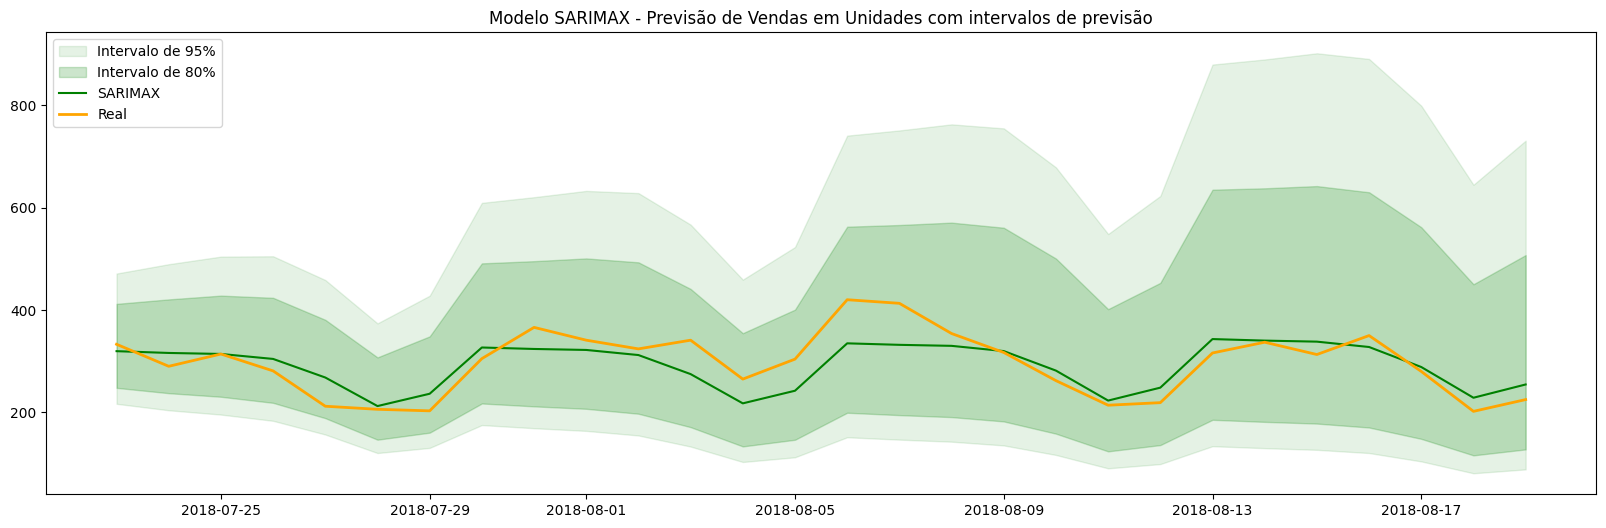

In [12]:
# Plotando a previsão do SARIMAX com os intervalos de previsão
fig, ax = plt.subplots(figsize = (20,6))

ax.fill_between(df_teste.index, intervalo_95.iloc[:, 0], intervalo_95.iloc[:, 1], color = 'green', alpha = 0.1, label = 'Intervalo de 95%')
ax.fill_between(df_teste.index, intervalo_80.iloc[:, 0], intervalo_80.iloc[:, 1], color = 'green', alpha = 0.2, label = 'Intervalo de 80%')
ax.plot(df_previsoes['SARIMAX'], label = 'SARIMAX', color = 'green')
ax.plot(df_previsoes['Real'], label = 'Real', color = 'orange', linewidth = 2)
plt.legend()
plt.title('Modelo SARIMAX - Previsão de Vendas em Unidades com intervalos de previsão')

plt.show()

In [13]:
# Avaliando a cobertura dos intervalos (percentual de dias em que a venda real ficou dentro do intervalo)
for nome, intervalo in [('80%', intervalo_80), ('95%', intervalo_95)]:
    dentro = (real >= intervalo.iloc[:, 0].values) & (real <= intervalo.iloc[:, 1].values)
    amplitude = (intervalo.iloc[:, 1] - intervalo.iloc[:, 0]).mean()
    print('Intervalo de {}: cobertura de {:.0f}% dos dias | amplitude média de {:.0f} unidades'.format(nome, 100 * dentro.mean(), amplitude))

Intervalo de 80%: cobertura de 100% dos dias | amplitude média de 306 unidades
Intervalo de 95%: cobertura de 100% dos dias | amplitude média de 499 unidades


- Todos os dias da base de teste ficaram dentro dos intervalos de 80% e de 95%. Isso indica que os intervalos são conservadores (mais largos que o necessário), o que é coerente com o histórico: o modelo foi treinado com períodos de alta incerteza (Black Friday, greve e Copa) e considera essa incerteza ao projetar o futuro. Além disso, a amplitude dos intervalos aumenta ao longo do horizonte, já que a incerteza se acumula a cada dia previsto.
- Para o planejamento, o intervalo de 80% pode ser utilizado como cenário pessimista e otimista. Para o dimensionamento de estoques de segurança, uma alternativa mais precisa é utilizar os erros observados no backtest, que representam o desempenho real do modelo.

### Visão semanal para o planejamento

- O planejamento logístico e financeiro normalmente é feito em base semanal ou mensal. Por isso, as previsões diárias são agrupadas por semana para avaliar o erro nesse nível.

In [14]:
# Agrupando as vendas reais e as previsões por semana (segunda a domingo)
df_semanal = df_previsoes.resample('W-SUN').sum()
df_semanal.index = [(fim - pd.Timedelta(days = 6)).strftime('%d/%m') + ' a ' + fim.strftime('%d/%m') for fim in df_semanal.index]
df_semanal.round(0)

,Seasonal Naive,ARIMA,SARIMA,SARIMAX,XGBoost,LightGBM,Real
23/07 a 29/07,1835,1827.0,1951.0,1971.0,1694.0,1700.0,1839
30/07 a 05/08,1835,1807.0,1987.0,2019.0,1690.0,1704.0,2246
06/08 a 12/08,1835,1800.0,2026.0,2069.0,1679.0,1858.0,2199
13/08 a 19/08,1835,1796.0,2065.0,2121.0,1490.0,1624.0,2023


In [15]:
# Calculando o WMAPE e o erro total no nível semanal
resultados_semanais = pd.DataFrame({modelo : calcular_metricas(df_semanal['Real'].values, df_semanal[modelo].values) for modelo in previsoes}).T
resultados_semanais[['WMAPE (%)', 'Erro total (%)']].sort_values('WMAPE (%)').round(2)

,WMAPE (%),Erro total (%)
SARIMAX,7.06,-1.53
SARIMA,7.06,-3.34
Seasonal Naive,11.64,-11.64
ARIMA,12.97,-12.97
LightGBM,17.12,-17.12
XGBoost,21.13,-21.13


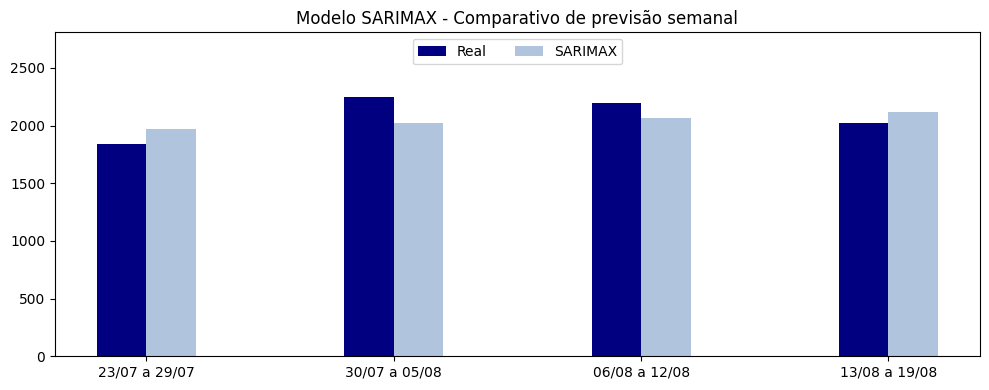

In [16]:
# Configurando gráfico
bar_width = 0.2
categories = df_semanal.index.values
x = np.arange(len(categories))

# Plotar resultados
fig, ax = plt.subplots(figsize = (10,4))
ax.bar(x - bar_width / 2, df_semanal['Real'], width = bar_width, label = 'Real', color = 'navy')
ax.bar(x + bar_width / 2, df_semanal['SARIMAX'], width = bar_width, label = 'SARIMAX', color = 'lightsteelblue')

# Configurações do Gráfico
plt.xticks(x, categories)
ax.set_ylim(0, 1.25 * df_semanal[['Real', 'SARIMAX']].max().max())
plt.legend(loc = 'upper center', ncol = 2)
plt.title('Modelo SARIMAX - Comparativo de previsão semanal')
plt.tight_layout()

plt.show()

- No nível semanal, o WMAPE do SARIMAX cai para 7,1%: os erros diários para mais e para menos se compensam dentro de cada semana. A primeira e a última semana foram superestimadas (em 7% e 4%, respectivamente), enquanto a segunda e a terceira foram subestimadas (em 10% e 6%), principalmente pelo aumento de vendas no início de agosto, que inclui o pico de 06 e 07/08/2018.
- No total das 4 semanas, a previsão do SARIMAX foi de 8.159 unidades, contra 8.307 vendidas, um erro de -1,8%. Para um planejamento mensal, esse é um nível de precisão bastante adequado.

### Conclusões

- **Modelo final**: o **SARIMAX(1,1,1)(0,1,1)7 com variáveis de eventos** foi o melhor modelo tanto no backtest da etapa 4 (WMAPE médio de 18,6%) quanto na base de teste (WMAPE de 9,8%), com 41% de melhoria em relação ao Seasonal Naive no teste. Ele é o modelo escolhido para a previsão de vendas.
- **Precisão para o negócio**: no teste, o erro foi de 9,8% no nível diário, 7,1% no nível semanal e -1,8% no total das 4 semanas. Considerando também o backtest, a expectativa em produção é de erros diários em torno de 10% em períodos normais, podendo superar 25% em períodos com eventos não previstos.
- **Modelos estatísticos x machine learning**: com menos de dois anos de histórico, os modelos estatísticos foram mais precisos e mais estáveis. Os modelos de machine learning dependem de features com defasagem de 28 dias e demoraram a reagir à recuperação das vendas após a Copa do Mundo.
- **Incerteza**: o SARIMAX fornece intervalos de previsão, que podem ser utilizados como cenários pessimista e otimista no planejamento.
- **Próximos passos**:
  - Incluir novos eventos como variáveis (campanhas promocionais, grandes eventos esportivos), já que os maiores erros do projeto vieram de eventos não representados nos dados.
  - Retreinar o modelo periodicamente (por exemplo, a cada semana), incorporando as vendas mais recentes.
  - Com mais histórico, incluir a sazonalidade anual e reavaliar os modelos de machine learning, inclusive com a previsão recursiva.